# Car Prices (Regression)
## CS 1783 Artificial Intelligence Programming
### Jacob Shultz

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import stats
from copy import deepcopy
import re

## 1. Load analyze and clean data

In [2]:
path = 'datasets/used_cars.csv'

df = pd.read_csv(path, header=0, na_values='?')
print(df.shape)
df.head()

(4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [3]:
# clean up this collosal mess
# forced to manually one-hot everything

df['fuel_type'] = df['fuel_type'].replace(['not supported', '–'], np.nan)
df['engine'] = df['engine'].replace('–', np.nan)
df['int_col'] = df['int_col'].replace('–', np.nan)

df['price'] = df['price'].str.replace('$', '').str.replace(',', '').astype(float)

df['milage'] = df['milage'].str.replace(' mi.', '').str.replace(',', '').astype(float)

brand_enc = OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist', sparse_output=False).set_output(transform="pandas")
brand_ohe = brand_enc.fit_transform(df[['brand']])
df = pd.concat([df.drop(columns='brand'), brand_ohe], axis=1)

model_enc = OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist', sparse_output=False).set_output(transform="pandas")
model_ohe = model_enc.fit_transform(df[['model']])
df = pd.concat([df.drop(columns='model'), model_ohe], axis=1)

df['age'] = 2026 - df['model_year']
df = df.drop(columns=['model_year'])

df['fuel_type'] = df['fuel_type'].fillna('unknown')
df = pd.get_dummies(df, columns=['fuel_type'], dtype=float)


# things to attempt to parse from engine feature
# - HP
# - L
# - Cylinder #
# - is electric
e = df["engine"]

df["hp"] = pd.to_numeric(e.str.extract(r"(\d+\.?\d*)HP")[0], errors="coerce")
df['hp'] = df['hp'].fillna(df['hp'].mean())
df["liters"] = pd.to_numeric(e.str.extract(r"(\d+\.\d+)\s*(?:L\b|Liter)")[0], errors="coerce")
df['liters'] = df['liters'].fillna(df['liters'].mean())

cyl = e.str.extract(r"(?:(\d+)\s*Cylinder|[VIWH]-?(\d+)\b|Flat\s*(\d+))")
df["cylinders"] = pd.to_numeric(cyl[0].fillna(cyl[1]).fillna(cyl[2]), errors="coerce")
df['cylinders'] = df['cylinders'].fillna(df['cylinders'].mean())
df["is_electric"] = e.str.contains("Electric", case=False, na=False).astype(int)
df = df.drop(columns="engine")

# sort of the same situation with transmission. not a car guy, lol
t = df["transmission"]
df["is_manual"] = t.str.contains(r"m/t|manual(?! mode)|\bmt\b", case=False).astype(int)
df["gears"] = pd.to_numeric(t.str.extract(r"(\d+)[\s-]*(?:speed|spd)", flags=re.I)[0], errors="coerce")
df['gears'] = df['gears'].fillna(df['gears'].mean())
df = df.drop(columns="transmission")

ext_col_enc = OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist', sparse_output=False).set_output(transform="pandas")
ext_col_ohe = ext_col_enc.fit_transform(df[['ext_col']])
df = pd.concat([df.drop(columns='ext_col'), ext_col_ohe], axis=1)

int_col_enc = OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist', sparse_output=False).set_output(transform="pandas")
int_col_ohe = int_col_enc.fit_transform(df[['int_col']])
df = pd.concat([df.drop(columns='int_col'), int_col_ohe], axis=1)

df['accident'] = df['accident'].fillna('unknown')
df = pd.get_dummies(df, columns=['accident'], dtype=float)

df['clean_title'] = df['clean_title'].fillna('unknown')
df = pd.get_dummies(df, columns=['clean_title'], dtype=float)
  
print(df.info())
print()
for col in df:
  print('-'*100)
  uniques = df[col].unique()
  print(f"{col}: {uniques}\nTotal:{len(uniques)}\n")
  print(f"{df[col].value_counts()}\n")

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 85 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   milage                                           4009 non-null   float64
 1   price                                            4009 non-null   float64
 2   brand_Acura                                      4009 non-null   float64
 3   brand_Audi                                       4009 non-null   float64
 4   brand_BMW                                        4009 non-null   float64
 5   brand_Bentley                                    4009 non-null   float64
 6   brand_Buick                                      4009 non-null   float64
 7   brand_Cadillac                                   4009 non-null   float64
 8   brand_Chevrolet                                  4009 non-null   float64
 9   brand_Chrysler                           

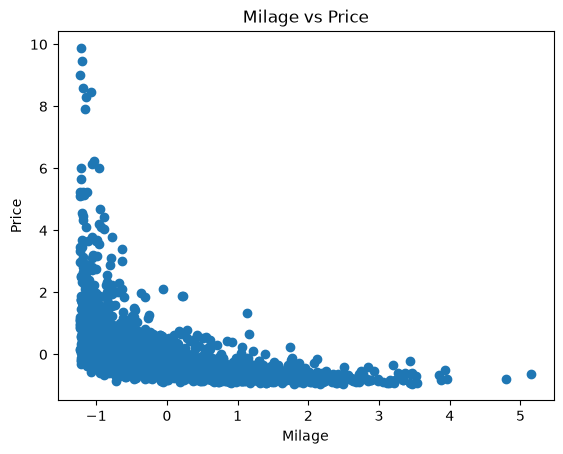

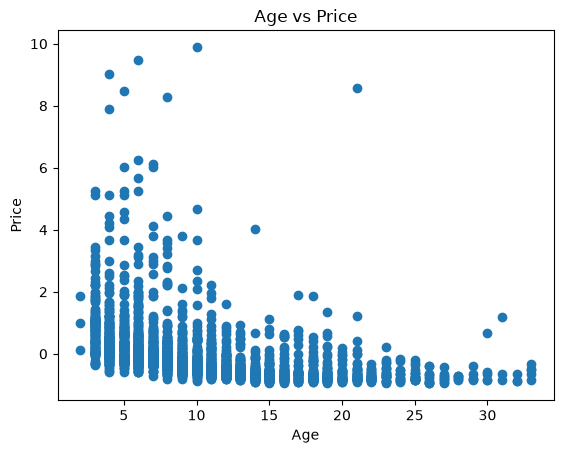

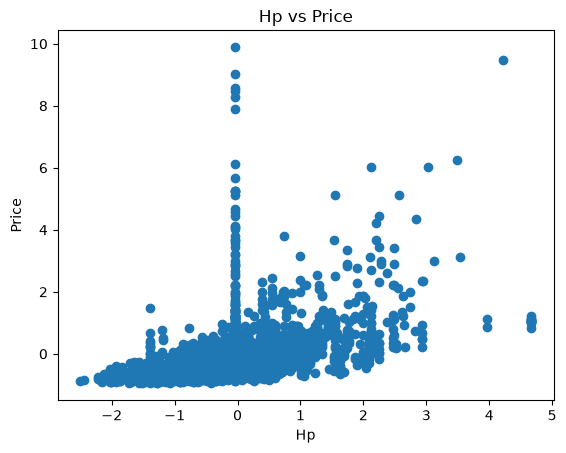

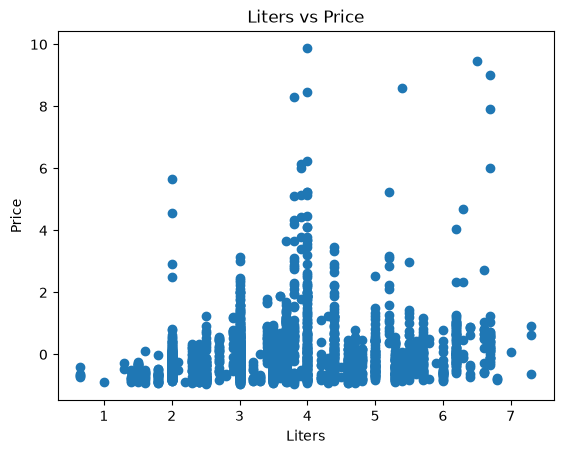

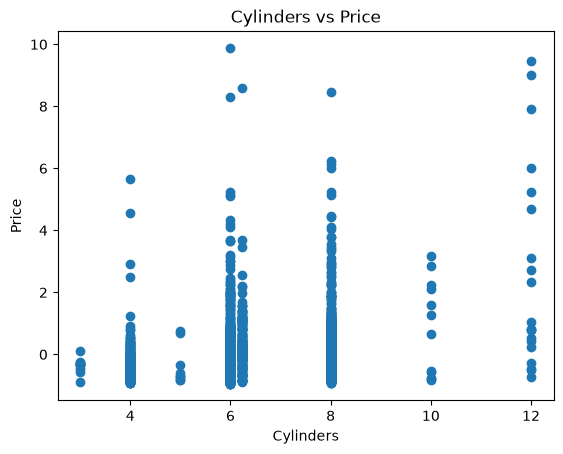

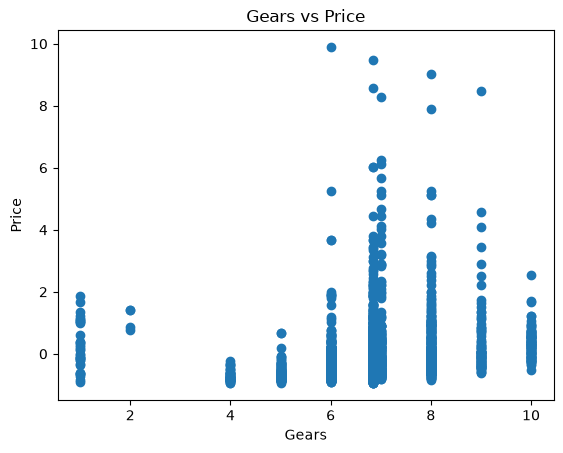

In [4]:
# some graphs, looking for outliers.

def quickplot(x: str, y: str):
    plt.scatter(df[x], df[y])
    plt.xlabel(x.capitalize())
    plt.ylabel(y.capitalize())
    plt.title(f"{x.capitalize()} vs {y.capitalize()}")
    plt.show()

def plot_all():
    quickplot('milage', 'price')
    quickplot('age', 'price')
    quickplot('hp', 'price')
    quickplot('liters', 'price')
    quickplot('cylinders', 'price')
    quickplot('gears', 'price')

df = df[(np.abs(stats.zscore(df)) < 6).all(axis=1)] # squash outliers, drop rows with outliers in any col outside 6 std devs

# scale columns with big numbers
scaler = StandardScaler()
price_scaler = StandardScaler()
df[['milage', 'hp']] = scaler.fit_transform(df[['milage', 'hp']])
df[['price']] = price_scaler.fit_transform(df[['price']])   # to reverse later

plot_all()

In [5]:
print(df.shape)
df.head()

(2289, 85)


,milage,price,brand_Acura,brand_Audi,brand_BMW,brand_Bentley,brand_Buick,brand_Cadillac,brand_Chevrolet,brand_Chrysler,...,int_col_Orange,int_col_Red,int_col_White,int_col_nan,int_col_infrequent_sklearn,accident_At least 1 accident or damage reported,accident_None reported,accident_unknown,clean_title_Yes,clean_title_unknown
0,-0.253301,-0.767422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.801123,0.218890,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-1.041029,-0.217489,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6,0.378182,-0.306529,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
8,-0.780762,-0.063235,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [6]:
# random train-test-split
X = df.drop(columns='price')
y = df.iloc[:, 1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
y_train.head()

(1831, 84) (1831,)
(458, 84) (458,)


1491   -0.128406
2440   -0.629377
3648    0.383587
3937   -0.506917
3297   -0.375551
Name: price, dtype: float64

In [7]:
# convert Pandas DataFrames to Pytorch tensors
X_train_tsor = torch.tensor(X_train.to_numpy(dtype=np.float32), dtype=torch.float32)
y_train_tsor = torch.tensor(y_train.to_numpy(dtype=np.float32), dtype=torch.float32)

X_test_tsor = torch.tensor(X_test.to_numpy(dtype=np.float32), dtype=torch.float32)
y_test_tsor = torch.tensor(y_test.to_numpy(dtype=np.float32), dtype=torch.float32)

print(X_train_tsor.shape, y_train_tsor.shape)
print(X_test_tsor.shape, y_test_tsor.shape)

torch.Size([1831, 84]) torch.Size([1831])
torch.Size([458, 84]) torch.Size([458])


## 2. Build Neural Network

In [8]:
# batches
train_tsor_dataset = TensorDataset(X_train_tsor, y_train_tsor)

train_batches = DataLoader(
    train_tsor_dataset,
    batch_size=64,
    shuffle=True
)

In [9]:
# model = torch.nn.Sequential(
#         # input
#         torch.nn.Linear(84, 100),
#         torch.nn.ReLU(),

#         # Hidden
#         torch.nn.Linear(100, 100),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.3),

#         torch.nn.Linear(100, 80),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.3),
        
#         torch.nn.Linear(80, 60),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.3),

#         torch.nn.Linear(60, 40),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.3),

#         torch.nn.Linear(40, 30),
#         torch.nn.ReLU(),
#         torch.nn.Dropout(0.3),

#         torch.nn.Linear(30, 20),
#         torch.nn.ReLU(),

#         # Output
#         torch.nn.Linear(20, 1),
# )

In [10]:
model = torch.nn.Sequential(
        # input
        torch.nn.Linear(84, 70),
        torch.nn.ReLU(),
        
        # Hidden
        torch.nn.Linear(70, 55),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.2),

        torch.nn.Linear(55, 35),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.2),

        torch.nn.Linear(35, 20),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.2),

        # Output
        torch.nn.Linear(20, 1),
)

In [11]:
# loss_function = torch.nn.MSELoss()
loss_function = torch.nn.L1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

In [12]:
# training
epochs = 100
train_losses = []
val_losses = []
log: str = "Training:\n"
best_model = None
overfit_count = 0
patience = 10
intercepted = False

def log_print(msg: str, log: str):
    print(msg)
    log += msg + "\n"
    return log


for epoch in range(epochs):
    model.train()
    avg_loss = 0
    epoch_losses = []

    for inputs, outputs in train_batches:
        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        preds = model(inputs)

        # Calculate Loss
        loss = loss_function(preds, outputs.unsqueeze(1))

        # Gradients
        loss.backward()
        epoch_losses.append(loss.item())

        # Update weights
        optimizer.step()

    avg_train_loss = sum(epoch_losses) / len(epoch_losses)
    train_losses.append(avg_train_loss)


    model.eval()
    with torch.no_grad():
        preds = model(X_test_tsor)
        avg_test_loss = loss_function(preds, y_test_tsor.unsqueeze(1))
        if best_model is None or avg_test_loss.item() < min(val_losses):
            best_model = deepcopy(model.state_dict())
        val_losses.append(avg_test_loss.item())

    if intercepted and avg_test_loss.item() > avg_train_loss:
        overfit_count += 1
    elif not intercepted and avg_test_loss.item() < avg_train_loss:
        log = log_print(f"The losses intercepted at epoch {epoch + 1}: Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss.item():.6f}", log)
        intercepted = True
    else:
        overfit_count = 0

    if overfit_count >= patience:
        log = log_print(f"Early stopping at epoch {epoch + 1}: Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss.item():.6f}", log)
        break

    if (epoch + 1) % (epochs // 10) == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}\t"
            f"Train Loss: {train_losses[-1]:.6f}\t"
            f"Test Loss: {val_losses[-1]:.6f}"
        )

    log += f"Epoch {epoch + 1}/{epochs}\tTrain Loss: {train_losses[-1]:.6f}\tTest Loss: {val_losses[-1]:.6f}\n"

The losses intercepted at epoch 1: Train Loss: 0.480296, Test Loss: 0.309248
Epoch 10/100	Train Loss: 0.302020	Test Loss: 0.247911
Epoch 20/100	Train Loss: 0.265589	Test Loss: 0.217882
Epoch 30/100	Train Loss: 0.267647	Test Loss: 0.236312
Epoch 40/100	Train Loss: 0.257829	Test Loss: 0.225642
Epoch 50/100	Train Loss: 0.272558	Test Loss: 0.230172
Epoch 60/100	Train Loss: 0.241394	Test Loss: 0.241115
Epoch 70/100	Train Loss: 0.226534	Test Loss: 0.218489
Epoch 80/100	Train Loss: 0.243517	Test Loss: 0.230376
Epoch 90/100	Train Loss: 0.236108	Test Loss: 0.216146
Epoch 100/100	Train Loss: 0.238703	Test Loss: 0.214048


In [13]:
# validation
if best_model is not None:
    model.load_state_dict(best_model)

model.eval()

def compute_dollar_loss(preds, targets):
    pred_dollars = price_scaler.inverse_transform(preds.detach().cpu().numpy().reshape(-1, 1)).flatten()
    actual_dollars = price_scaler.inverse_transform(targets.detach().cpu().numpy().reshape(-1, 1)).flatten()
    
    return torch.mean(torch.abs(torch.tensor(pred_dollars) - torch.tensor(actual_dollars)))

with torch.no_grad():

  preds = model(X_test_tsor)
  loss = loss_function(preds, y_test_tsor.unsqueeze(1))
  dollar_loss = compute_dollar_loss(preds, y_test_tsor)

  print(f"Best Test Loss: {loss.item():.6f}")
  print(f"Best Test Loss in Dollars: {dollar_loss.item():.6f}")
  log += f"\nValidation\n"
  log += f"Best Test Loss: {loss.item():.6f}\n"
  log += f"Best Test Loss in Dollars: {dollar_loss.item():.6f}\n"


Best Test Loss: 0.206885
Best Test Loss in Dollars: 9291.784180


## 3. Output metrics

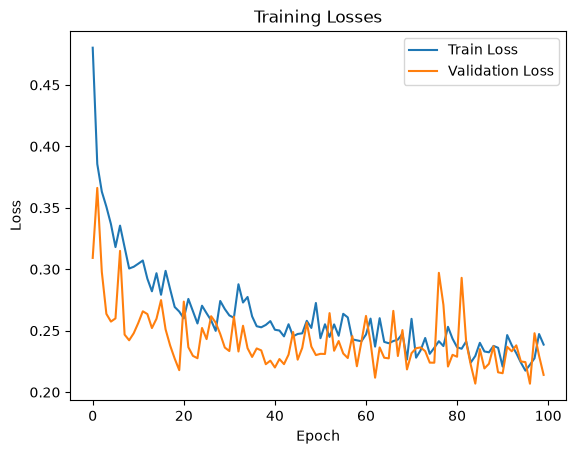

In [14]:
# plot metrics
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training Losses')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [15]:
with open("log.txt", "w") as f:
    f.write(log)

In [16]:
def draw_network(model, input_labels=None, output_labels=None, threshold=0.0):

    layers = [layer for layer in model if isinstance(layer, torch.nn.Linear)]

    sizes = [layers[0].in_features]
    sizes += [layer.out_features for layer in layers]

    layer_spacing = 1.5
    neuron_spacing = 0.22
    x_positions = np.arange(len(sizes)) * layer_spacing
    max_neurons = max(sizes)
    half_height = (max_neurons - 1) * neuron_spacing / 2
    fig, ax = plt.subplots(
        figsize=(
            max(14, (x_positions[-1] + 2) * 0.9),
            max(8, (max_neurons * neuron_spacing + 2.5) * 0.9),
        )
    )
    neuron_positions = []

    # ---------------------------------------------------------
    # Draw neurons
    # ---------------------------------------------------------

    for layer_num, size in enumerate(sizes):

        y_positions = (np.arange(size) - (size - 1) / 2) * neuron_spacing
        positions = []

        for neuron_num, y in enumerate(y_positions):

            x = x_positions[layer_num]

            circle = plt.Circle(
                (x, y),
                0.06,
                fill=True,
                zorder=3
            )

            ax.add_patch(circle)

            positions.append((x, y))

            # Label input neurons
            if layer_num == 0 and input_labels is not None:
                ax.text(
                    x - 0.15,
                    y,
                    input_labels[neuron_num],
                    ha="right",
                    va="center",
                    fontsize=11
                )

            # Label output neurons
            if layer_num == len(sizes) - 1 and output_labels is not None:
                ax.text(
                    x + 0.15,
                    y,
                    output_labels[neuron_num],
                    ha="left",
                    va="center",
                    fontsize=11
                )

            # -------------------------------------------------
            # Show bias for every neuron except input neurons
            # -------------------------------------------------

            if layer_num > 0:

                # Linear layer that feeds this neuron
                layer = layers[layer_num - 1]

                bias = layer.bias.detach().cpu().numpy()[neuron_num]

                ax.text(
                    x,
                    y - 0.1,
                    f"b={bias:.2f}",
                    ha="center",
                    va="top",
                    fontsize=8
                )

        neuron_positions.append(positions)


    # ---------------------------------------------------------
    # Draw weighted connections
    # ---------------------------------------------------------

    for layer_num, layer in enumerate(layers):

        weights = layer.weight.detach().cpu().numpy()

        max_weight = np.max(np.abs(weights))

        for destination in range(weights.shape[0]):

            for source in range(weights.shape[1]):

                weight = weights[destination, source]

                if abs(weight) < threshold:
                    continue

                x1, y1 = neuron_positions[layer_num][source]
                x2, y2 = neuron_positions[layer_num + 1][destination]

                strength = abs(weight) / max_weight

                # Exaggerate differences between weak and strong weights
                linewidth = 0.15 + (strength ** 2.5) * 8.0

                # Positive = green, negative = red
                color = "green" if weight >= 0 else "red"

                ax.plot(
                    [x1, x2],
                    [y1, y2],
                    color=color,
                    linewidth=linewidth,
                    alpha=0.5,
                    zorder=1
                )


    # ---------------------------------------------------------
    # Layer labels
    # ---------------------------------------------------------

    ax.text(
        x_positions[0], half_height + 0.7,
        "Input",
        ha="center",
        fontsize=12
    )

    for i in range(1, len(sizes) - 1):
        ax.text(
            x_positions[i], half_height + 0.7,
            f"Hidden\n{sizes[i]}",
            ha="center",
            fontsize=12
        )

    ax.text(
        x_positions[-1], half_height + 0.7,
        "Output",
        ha="center",
        fontsize=12
    )

    ax.set_xlim(-1, x_positions[-1] + 1)
    ax.set_ylim(-half_height - 1, half_height + 1.5)
    ax.set_aspect("equal", adjustable="box")

    ax.axis("off")

    plt.show()

In [17]:
# draw_network(model)